In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

def mejorar_iluminacion_hsv(img_bgr, titulo):
    # Convertir de BGR a RGB (para visualizar) y de BGR a HSV
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)

    # Separar los canales H (Matiz), S (Saturación) y V (Valor/Iluminación)
    h, s, v = cv2.split(img_hsv)

    # Aplicar ecualización de histograma únicamente al canal V
    v_ecualizado = cv2.equalizeHist(v)

    # Unir los canales nuevamente y regresar al espacio RGB
    hsv_mejorado = cv2.merge([h, s, v_ecualizado])
    rgb_mejorado = cv2.cvtColor(hsv_mejorado, cv2.COLOR_HSV2RGB)

    # Mostrar comparativa de imágenes e histogramas del canal V
    plt.figure(figsize=(12, 8))

    plt.subplot(2, 2, 1)
    plt.imshow(img_rgb)
    plt.title(f"{titulo} - Original")
    plt.axis("off")

    plt.subplot(2, 2, 2)
    plt.hist(v.ravel(), bins=256, range=[0, 256], color="dimgray")
    plt.title("Histograma Canal V (Original)")
    plt.xlabel("Intensidad (0 - 255)")
    plt.ylabel("Frecuencia")
    plt.xlim([0, 256])

    plt.subplot(2, 2, 3)
    plt.imshow(rgb_mejorado)
    plt.title(f"{titulo} - Iluminación Mejorada (HSV)")
    plt.axis("off")

    plt.subplot(2, 2, 4)
    plt.hist(v_ecualizado.ravel(), bins=256, range=[0, 256], color="darkorange")
    plt.title("Histograma Canal V (Ecualizado)")
    plt.xlabel("Intensidad (0 - 255)")
    plt.ylabel("Frecuencia")
    plt.xlim([0, 256])

    plt.tight_layout()
    plt.show()

Ejercicio 1

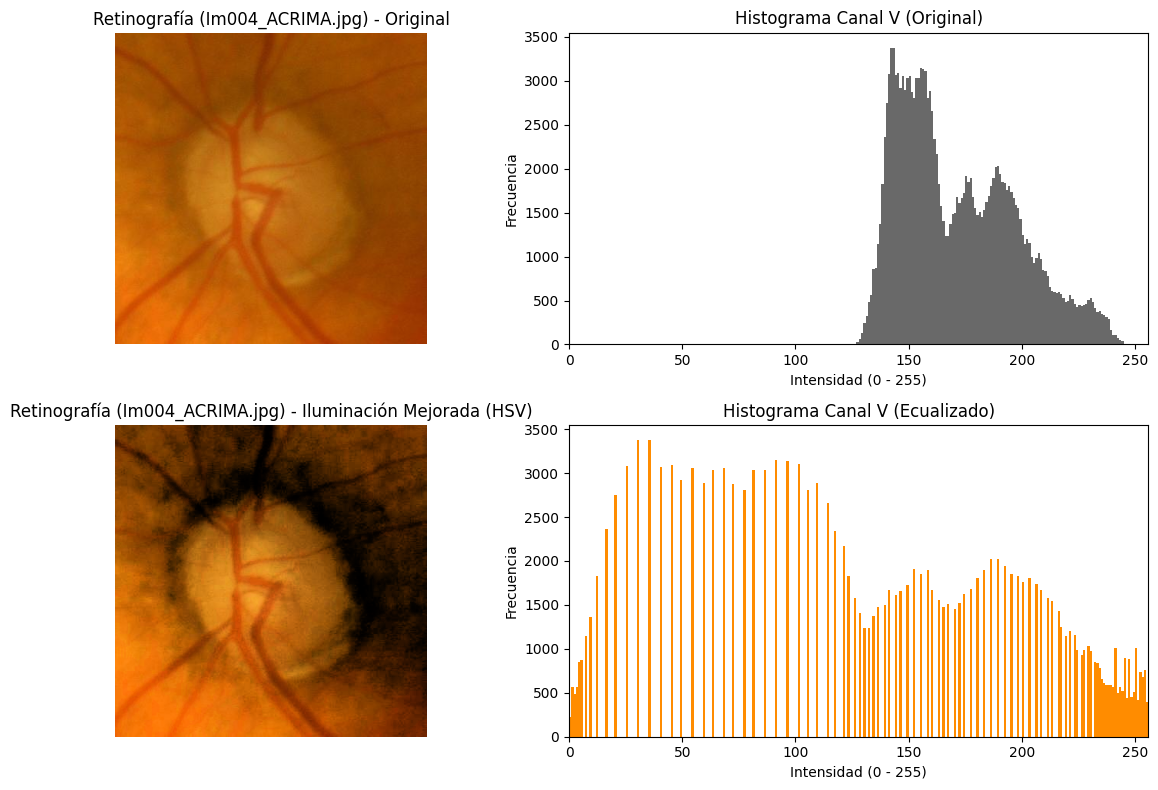

In [2]:
# Descargar Im004_ACRIMA.jpg directamente desde GitHub
url_acrima = "https://raw.githubusercontent.com/dilp90/PDI/main/Imagenes/Im004_ACRIMA.jpg"
urllib.request.urlretrieve(url_acrima, "Im004_ACRIMA.jpg")

img_acrima = cv2.imread("Im004_ACRIMA.jpg")
mejorar_iluminacion_hsv(img_acrima, "Retinografía (Im004_ACRIMA.jpg)")

Ejercicio 2

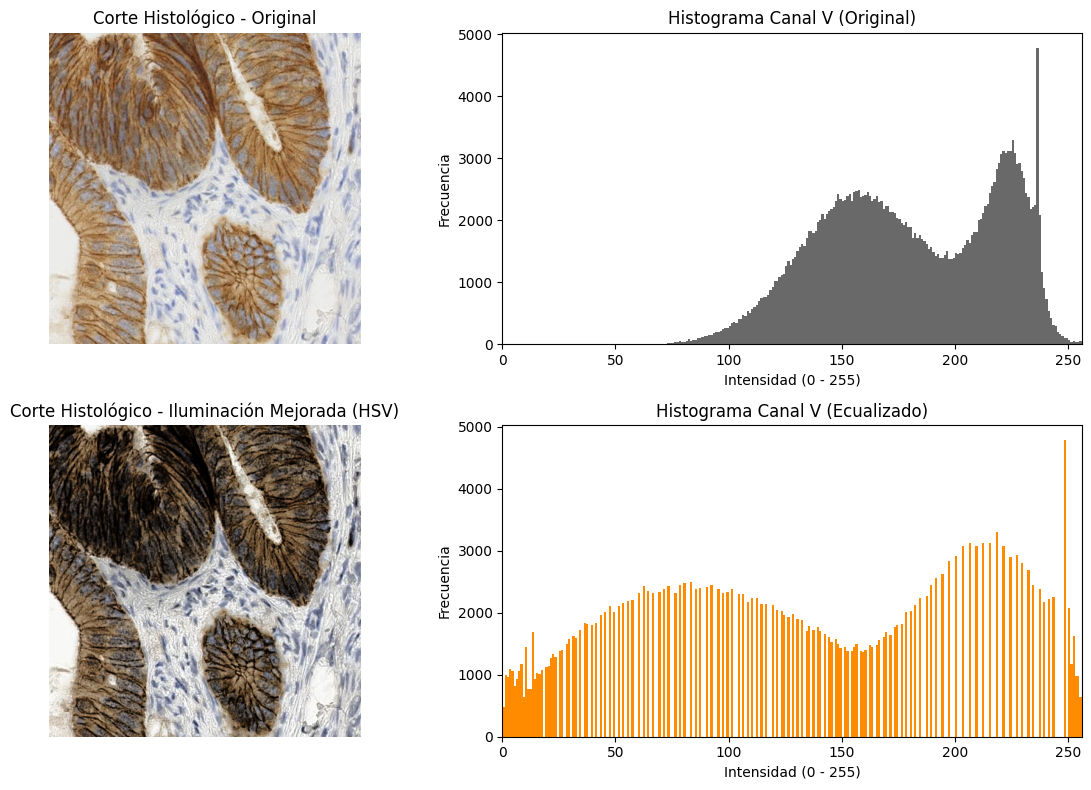

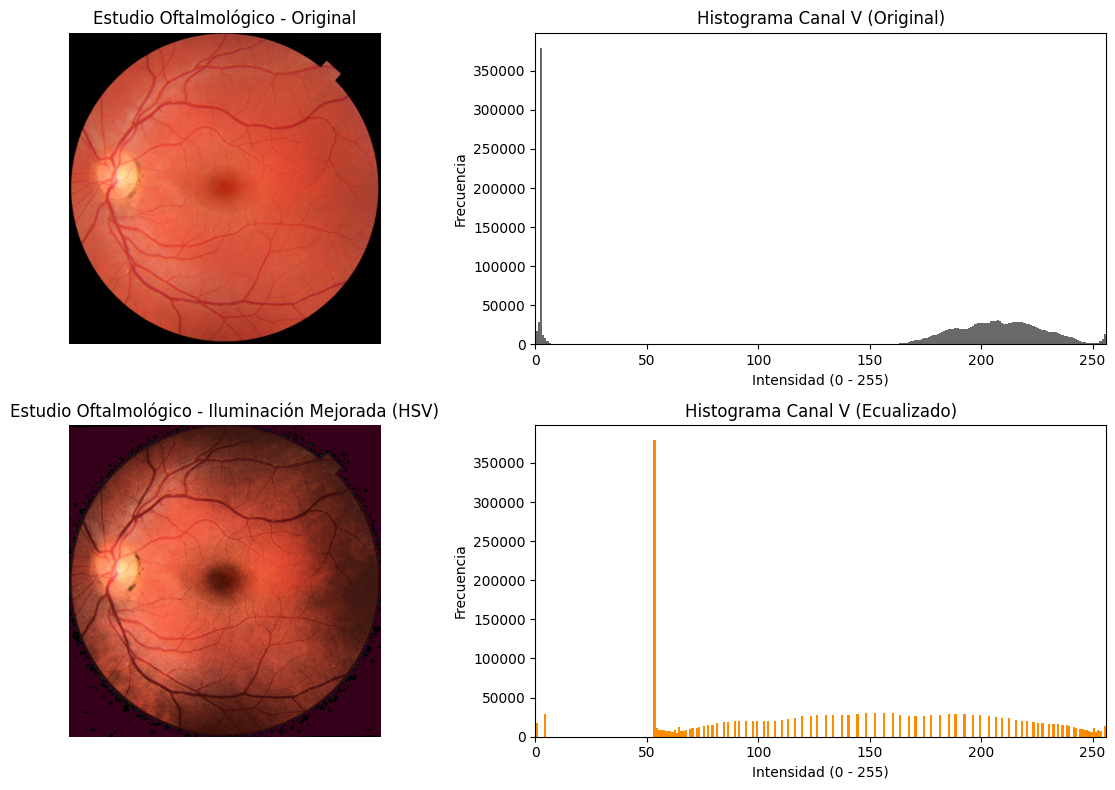

In [3]:
from skimage import data

# 1. Corte histológico con tinción inmunohistoquímica
img_histologia_bgr = cv2.cvtColor(data.immunohistochemistry(), cv2.COLOR_RGB2BGR)
mejorar_iluminacion_hsv(img_histologia_bgr, "Corte Histológico")

# 2. Estudio oftalmológico de retina
img_retina2_bgr = cv2.cvtColor(data.retina(), cv2.COLOR_RGB2BGR)
mejorar_iluminacion_hsv(img_retina2_bgr, "Estudio Oftalmológico")